<a href="https://colab.research.google.com/github/amansingh4847/NLP/blob/main/unit2/Topic%20Modeling%20using%20Latent%20Dirichlet%20Allocation%20(LDA).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


TOPIC MODELING USING LDA


Topic 1:
learning, data, cricket, popular, football, involves, techniques, science, analysis, networks

Topic 2:
machine, computers, intelligence, artificial, programming, learning, software, problems, complex, helps

Topic 3:
software, technology, applications, requires, development, coding, debugging, testing, companies, develop

DOCUMENT TOPIC ASSIGNMENTS

                                                                Document Dominant Topic  Topic Probability
Machine learning and artificial intelligence are transforming technology        Topic 2              0.899
         Deep learning uses neural networks for intelligent applications        Topic 1              0.914
                   Python programming is widely used in machine learning        Topic 2              0.902
          Artificial intelligence helps computers solve complex problems        Topic 2              0.916
     Data science involves data analysis and machine learning techniques   

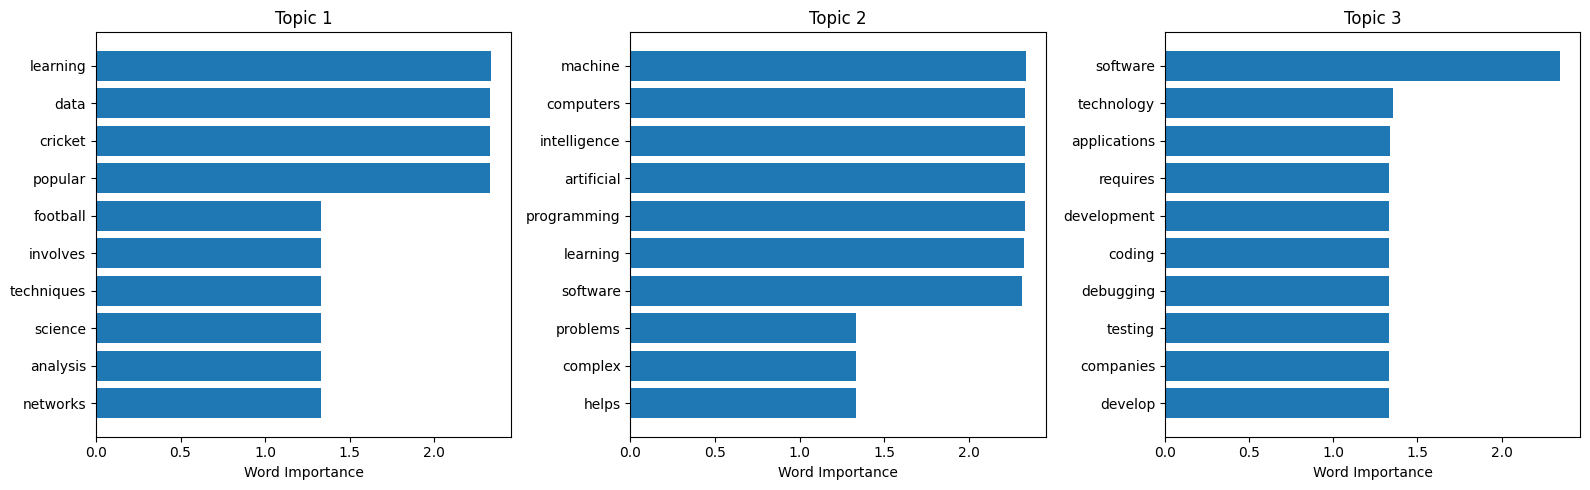

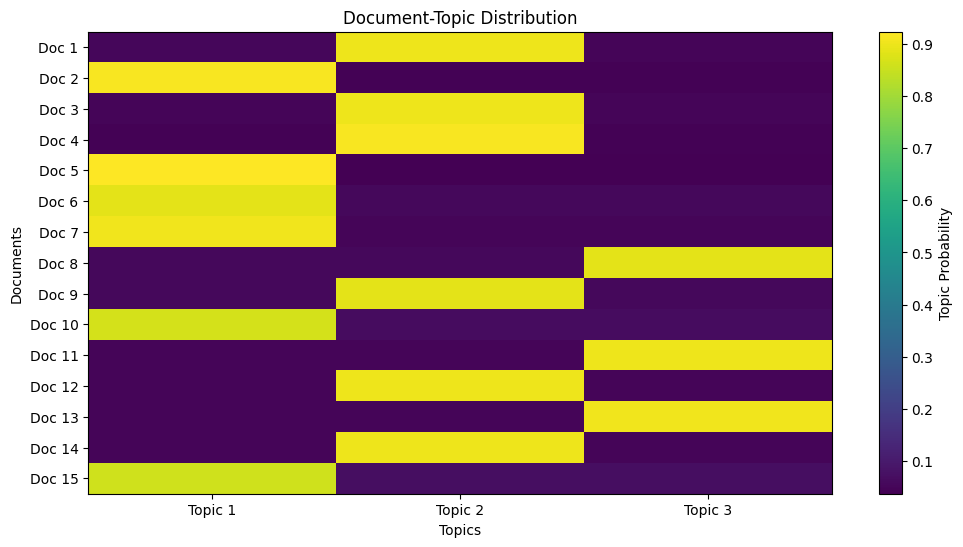


LDA Topic Modeling Completed Successfully!


In [5]:

# Topic Modeling using Latent Dirichlet Allocation (LDA)

!pip install -q scikit-learn nltk matplotlib pandas

import nltk
nltk.download('stopwords', quiet=True)

import pandas as pd
import matplotlib.pyplot as plt

from nltk.corpus import stopwords
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

# Sample document dataset
documents = [
    "Machine learning and artificial intelligence are transforming technology",
    "Deep learning uses neural networks for intelligent applications",
    "Python programming is widely used in machine learning",
    "Artificial intelligence helps computers solve complex problems",
    "Data science involves data analysis and machine learning techniques",
    "Football is a popular sport played around the world",
    "Cricket players practice batting bowling and fielding",
    "Sports improve physical fitness and teamwork",
    "Football tournaments attract millions of fans",
    "Cricket is one of the most popular games in India",
    "Technology companies develop software and computer applications",
    "Programming languages help developers build software",
    "Software development requires coding testing and debugging",
    "Computers process information using hardware and software",
    "Technology is changing education and business"
]

# Text preprocessing
stop_words = set(stopwords.words('english'))

def preprocess(text):
    words = text.lower().split()
    return " ".join([
        word for word in words
        if word.isalpha() and word not in stop_words
    ])

cleaned_documents = [preprocess(doc) for doc in documents]

# Convert documents into document-term matrix
vectorizer = CountVectorizer(
    max_df=0.95,
    min_df=1,
    stop_words='english'
)

document_matrix = vectorizer.fit_transform(cleaned_documents)

# Train LDA model
num_topics = 3

lda_model = LatentDirichletAllocation(
    n_components=num_topics,
    random_state=42,
    max_iter=20,
    learning_method='batch'
)

lda_model.fit(document_matrix)

# Extract topic keywords
feature_names = vectorizer.get_feature_names_out()

print("\nTOPIC MODELING USING LDA\n")

for topic_index, topic in enumerate(lda_model.components_):
    top_words = [
        feature_names[i]
        for i in topic.argsort()[-10:][::-1]
    ]

    print(f"\nTopic {topic_index + 1}:")
    print(", ".join(top_words))

# Assign topics to documents
topic_distribution = lda_model.transform(document_matrix)

results = []

for i, distribution in enumerate(topic_distribution):
    dominant_topic = distribution.argmax()

    results.append({
        'Document': documents[i],
        'Dominant Topic': f"Topic {dominant_topic + 1}",
        'Topic Probability': round(distribution[dominant_topic], 3)
    })

df = pd.DataFrame(results)

print("\nDOCUMENT TOPIC ASSIGNMENTS\n")
print(df.to_string(index=False))

# Visualize topic-word distribution
fig, axes = plt.subplots(1, num_topics, figsize=(16, 5))

for i, ax in enumerate(axes):
    top_indices = lda_model.components_[i].argsort()[-10:][::-1]

    words = feature_names[top_indices]
    weights = lda_model.components_[i][top_indices]

    ax.barh(words[::-1], weights[::-1])
    ax.set_title(f"Topic {i + 1}")
    ax.set_xlabel("Word Importance")

plt.tight_layout()
plt.show()

# Visualize document-topic distribution
plt.figure(figsize=(12, 6))

plt.imshow(topic_distribution, aspect='auto', cmap='viridis')
plt.colorbar(label='Topic Probability')
plt.xlabel('Topics')
plt.ylabel('Documents')
plt.xticks(range(num_topics), [f"Topic {i+1}" for i in range(num_topics)])
plt.yticks(range(len(documents)), [f"Doc {i+1}" for i in range(len(documents))])
plt.title("Document-Topic Distribution")
plt.show()

print("\nLDA Topic Modeling Completed Successfully!")
